# Spam Email Detection with NLP
## Notebook 5 — Final Evaluation and Model Export
**Author: Tinashe Clifford Makandise**

### Purpose
Reconstruct the candidate selected in Notebook 4, fit its complete TF-IDF/classifier pipeline on the training partition, then evaluate the reserved test partition using the frozen decision rule. Export the exact evaluated pipeline for the app.

Run Notebooks 1–4 first. Save in `notebooks/` and run cells in order. Required packages: pandas, numpy, scikit-learn, matplotlib, joblib and threadpoolctl. No raw email excerpts are displayed or exported in the evaluation reports.

This notebook records final evaluation, not another model-selection round. Rerunning the same frozen experiment is reproducibility; changing the model after seeing test results turns this test set into development data and requires a new independent evaluation set.

In [1]:
from pathlib import Path
import json, hashlib, platform, time
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, joblib
from threadpoolctl import threadpool_limits
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             average_precision_score, confusion_matrix, classification_report,
                             precision_recall_curve)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPORTS, MODELS = ROOT / "reports", ROOT / "models"
FIGURES = REPORTS / "figures"
MODELS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
manifest = json.loads((REPORTS / "data_manifest.json").read_text(encoding="utf-8"))
selection_path = REPORTS / "selected_model.json"
selection_bytes = selection_path.read_bytes()
selection_hash = hashlib.sha256(selection_bytes).hexdigest()
selection = json.loads(selection_bytes)
train_path, test_path = ROOT / "data/processed/train.csv", ROOT / "data/processed/test.csv"
assert hashlib.sha256(train_path.read_bytes()).hexdigest() == manifest["train_file_sha256"] == selection["train_file_sha256"]
assert hashlib.sha256(test_path.read_bytes()).hexdigest() == manifest["test_file_sha256"]
assert hashlib.sha256((REPORTS / "feature_engineering_plan.json").read_bytes()).hexdigest() == selection["feature_plan_sha256"]
train = pd.read_csv(train_path, keep_default_na=False)
assert len(train) == manifest["train_rows"] and set(train.row_id) == set(manifest["train_row_ids"])
assert set(train.group_id) == set(manifest["train_groups"])
assert train.spam.isin([0, 1]).all() and train.text.str.strip().ne("").all()
print("Frozen candidate:", selection["selected_candidate"])
print("Decision rule:", selection["decision_rule"])
print(f"Verified {len(train):,} training rows and file integrity.")

Frozen candidate: logistic_regression__word_tfidf_stopwords
Decision rule: classifier.predict default; no threshold tuning
Verified 4,547 training rows and file integrity.


### 1. Fit the frozen pipeline on training data only
The vectorizer and classifier are saved together. This ensures that deployment uses exactly the vocabulary, IDF weights and preprocessing used during evaluation. Standard scikit-learn components avoid notebook-defined functions inside the serialized artifact.

All training rows are now available for fitting because candidate selection is complete. Do not combine the test rows into this fit: the exported model must match the model being evaluated.

In [2]:
settings = dict(selection["vectorizer_settings"])
settings["ngram_range"] = tuple(settings["ngram_range"])
if selection["model_name"] == "logistic_regression":
    classifier = LogisticRegression(**selection["classifier_settings"])
elif selection["model_name"] == "naive_bayes":
    classifier = MultinomialNB(**selection["classifier_settings"])
else:
    raise ValueError("Unsupported frozen classifier")
pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(**settings, stop_words=selection["stop_words"])),
    ("classifier", classifier),
])
start = time.perf_counter()
with threadpool_limits(limits=1):
    pipeline.fit(train.text, train.spam)
fit_seconds = time.perf_counter() - start
if selection["model_name"] == "logistic_regression":
    assert pipeline.named_steps["classifier"].n_iter_.max() < classifier.max_iter
assert list(pipeline.classes_) == [0, 1]
print("Pipeline fitted using training data only.")
print("Vocabulary size:", len(pipeline.named_steps["tfidf"].vocabulary_))
print(f"Fit time in this environment: {fit_seconds:.1f} seconds")

Pipeline fitted using training data only.
Vocabulary size: 30000
Fit time in this environment: 9.5 seconds


### 2. Open and verify the reserved test partition
Check row identities, labels, nonblank text and absence of normalised-group overlap. This grouping controls case/whitespace variants; it does not establish that all campaign-related or near-duplicate messages were separated.

Predict once using the standard classifier decision rule. A spam score is an uncalibrated model probability estimate. Do not use the test results to tune a threshold.

In [3]:
test = pd.read_csv(test_path, keep_default_na=False)
assert len(test) == manifest["test_rows"] and set(test.row_id) == set(manifest["test_row_ids"])
assert set(test.group_id) == set(manifest["test_groups"])
assert set(train.group_id).isdisjoint(set(test.group_id))
assert set(train.row_id).isdisjoint(set(test.row_id))
assert test.spam.isin([0, 1]).all() and test.text.str.strip().ne("").all()
y_test = test.spam.to_numpy()
predicted = pipeline.predict(test.text)
spam_score = pipeline.predict_proba(test.text)[:, list(pipeline.classes_).index(1)]
assert np.isfinite(spam_score).all() and ((spam_score >= 0) & (spam_score <= 1)).all()
tn, fp, fn, tp = confusion_matrix(y_test, predicted, labels=[0, 1]).ravel()
metrics = {
    "test_rows": len(test), "test_ham_rows": int((y_test == 0).sum()),
    "test_spam_rows": int((y_test == 1).sum()),
    "accuracy": accuracy_score(y_test, predicted),
    "spam_precision": precision_score(y_test, predicted, zero_division=0),
    "spam_recall": recall_score(y_test, predicted, zero_division=0),
    "spam_f1": f1_score(y_test, predicted, zero_division=0),
    "average_precision": average_precision_score(y_test, spam_score),
    "false_positive_rate": float(fp / (fp + tn)),
    "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
}
print(json.dumps(metrics, indent=2))
print(classification_report(y_test, predicted, labels=[0, 1], target_names=["Ham", "Spam"], digits=4, zero_division=0))

{
  "test_rows": 1148,
  "test_ham_rows": 874,
  "test_spam_rows": 274,
  "accuracy": 0.985191637630662,
  "spam_precision": 0.9885931558935361,
  "spam_recall": 0.948905109489051,
  "spam_f1": 0.9683426443202979,
  "average_precision": 0.9978814949874371,
  "false_positive_rate": 0.003432494279176201,
  "tn": 871,
  "fp": 3,
  "fn": 14,
  "tp": 260
}
              precision    recall  f1-score   support

         Ham     0.9842    0.9966    0.9903       874
        Spam     0.9886    0.9489    0.9683       274

    accuracy                         0.9852      1148
   macro avg     0.9864    0.9727    0.9793      1148
weighted avg     0.9852    0.9852    0.9851      1148



### 3. Visualise the final errors and ranking performance
The confusion matrix shows absolute error counts. Average precision summarises ranking; the precision-recall curve is descriptive and must not become a threshold-selection exercise on the test set. The horizontal reference is the spam share of this test partition.

Scores are row-weighted and conditional on this historical dataset and split. They are not proof of equivalent performance on a current inbox, other languages or new spam campaigns.

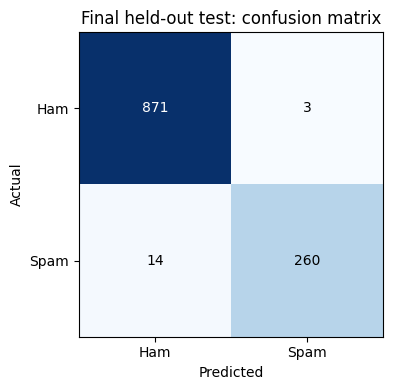

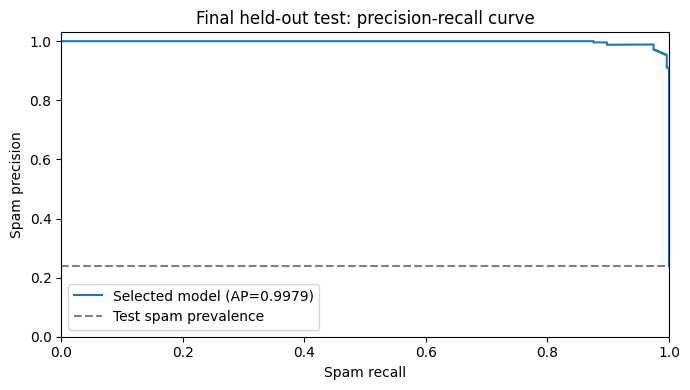

In [4]:
cm = confusion_matrix(y_test, predicted, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(cm, cmap="Blues")
for (i, j), value in np.ndenumerate(cm):
    ax.text(j, i, str(value), ha="center", va="center", color="white" if value > cm.max()/2 else "black")
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Ham", "Spam"], yticklabels=["Ham", "Spam"],
       xlabel="Predicted", ylabel="Actual", title="Final held-out test: confusion matrix")
plt.tight_layout()
plt.savefig(FIGURES / "05_test_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()
precision, recall, _ = precision_recall_curve(y_test, spam_score)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(recall, precision, label=f"Selected model (AP={metrics['average_precision']:.4f})")
ax.axhline(y_test.mean(), color="gray", linestyle="--", label="Test spam prevalence")
ax.set(xlabel="Spam recall", ylabel="Spam precision", xlim=(0, 1), ylim=(0, 1.03), title="Final held-out test: precision-recall curve")
ax.legend(loc="lower left")
plt.tight_layout()
plt.savefig(FIGURES / "05_test_precision_recall.png", dpi=150, bbox_inches="tight")
plt.show()

### 4. Save the exact evaluated model and reload it
Joblib stores the entire fitted pipeline. Only load model files from trusted sources: pickle-based formats can execute code. Preserve compatible library versions for deployment; a model file is not a substitute for the recorded environment.

Reload the exported artifact and check identical labels and numerical agreement on the same test inputs. This is a serialization check, not a new model-selection experiment. The exported pipeline remains fitted exclusively on training data.

In [5]:
model_path = MODELS / "spam_pipeline.joblib"
joblib.dump(pipeline, model_path, compress=3)
reloaded = joblib.load(model_path)
assert np.array_equal(reloaded.predict(test.text), predicted)
np.testing.assert_allclose(reloaded.predict_proba(test.text)[:, 1], spam_score, rtol=1e-12, atol=1e-12)
model_hash = hashlib.sha256(model_path.read_bytes()).hexdigest()
print("Exported:", model_path.name)
print("File size (MiB):", round(model_path.stat().st_size / 1024**2, 2))
print("Reloaded artifact matches original predictions and scores.")

Exported: spam_pipeline.joblib
File size (MiB): 0.53
Reloaded artifact matches original predictions and scores.


### 5. Input checks for the future app
Blank, punctuation-only and entirely out-of-vocabulary inputs should produce a helpful message rather than a confident classification. Reject those inputs before calling the classifier. This does not detect all unsupported languages or out-of-distribution emails: nonzero features only establish some vocabulary overlap.

Examples are invented interface checks, not additional labelled evaluation data. A “Ham” result must be described as “predicted ham”, not “safe” or “verified legitimate”. The app should not imply phishing detection or access attachments.

In [6]:
def predict_email(text, model=reloaded):
    if not isinstance(text, str) or not text.strip():
        return {"status": "invalid", "message": "Enter email text first."}
    features = model.named_steps["tfidf"].transform([text])
    if features.nnz == 0:
        return {"status": "unsupported", "message": "No recognised text features; enter a fuller email in English."}
    label = int(model.predict([text])[0])
    index = list(model.classes_).index(1)
    score = float(model.predict_proba([text])[0, index])
    return {"status": "ok", "prediction": "Spam" if label else "Ham", "spam_score": score}

assert predict_email("")["status"] == "invalid"
assert predict_email("   ")["status"] == "invalid"
assert predict_email("!!!")["status"] == "unsupported"
for text in ["Subject: team meeting tomorrow to discuss the project report", "Subject: claim your free cash prize click now"]:
    result = predict_email(text)
    assert result["status"] == "ok" and 0 <= result["spam_score"] <= 1
    print("Invented UI example:", result)
print("Input and serialization checks passed.")

Invented UI example: {'status': 'ok', 'prediction': 'Ham', 'spam_score': 0.13368889335050246}
Invented UI example: {'status': 'ok', 'prediction': 'Spam', 'spam_score': 0.7569800840184451}
Input and serialization checks passed.


### 6. Export metrics, metadata and deployment versions
The model metadata records its origin, training/test partition hashes, selected settings, dependency versions, model checksum and final results. No raw email text is needed by the future app. Deployment requires the model and metadata; these reports document how the result was obtained.

The generated versions file pins the core inference libraries used here. Streamlit will be added when building the app. Python should match the recorded version as closely as the hosting platform supports.

In [7]:
versions = {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
            "numpy": np.__version__, "pandas": pd.__version__, "joblib": joblib.__version__}
metadata = {
    "author": "Tinashe Clifford Makandise", "created_utc": datetime.now(timezone.utc).isoformat(),
    "source_url": manifest["source_url"], "selected_candidate": selection["selected_candidate"],
    "selected_settings": selection, "selection_file_sha256": selection_hash,
    "train_file_sha256": manifest["train_file_sha256"], "test_file_sha256": manifest["test_file_sha256"],
    "trained_on": "training partition only", "training_rows": len(train),
    "test_metrics": metrics, "label_mapping": {"0": "Ham", "1": "Spam"},
    "decision_rule": selection["decision_rule"], "model_file": model_path.name,
    "model_sha256": model_hash, "versions": versions,
    "limitations": ["Historical, source-specific English corpus", "Possible related campaigns and near-duplicates across groups",
                    "Uncalibrated probability estimates", "Not phishing detection or a safety guarantee"],
}
(MODELS / "model_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
(REPORTS / "final_test_metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
report = classification_report(y_test, predicted, labels=[0, 1], target_names=["Ham", "Spam"], output_dict=True, zero_division=0)
(REPORTS / "final_classification_report.json").write_text(json.dumps(report, indent=2), encoding="utf-8")
(MODELS / "inference_requirements.txt").write_text("\n".join(f"{name}=={versions[name]}" for name in ["scikit-learn", "numpy", "joblib"]) + "\n", encoding="utf-8")
assert selection_path.read_bytes() == selection_bytes
assert hashlib.sha256(train_path.read_bytes()).hexdigest() == manifest["train_file_sha256"]
assert hashlib.sha256(test_path.read_bytes()).hexdigest() == manifest["test_file_sha256"]
print("Saved pipeline, metadata, final reports and core inference versions.")
print(f"Held-out test accuracy {metrics['accuracy']:.2%}; spam F1 {metrics['spam_f1']:.2%}.")
print(f"Errors: {metrics['fp']} legitimate emails flagged; {metrics['fn']} spam messages missed.")

Saved pipeline, metadata, final reports and core inference versions.
Held-out test accuracy 98.52%; spam F1 96.83%.
Errors: 3 legitimate emails flagged; 14 spam messages missed.


### Conclusion and next step
The exact selected model has been evaluated and exported without fitting on test rows. Report the computed final test metrics above in the README and portfolio, identifying the dataset and evaluation method. Do not substitute development CV scores for held-out results or claim a guaranteed response time without measuring deployment.

**Next: Build the Streamlit app.** Load `models/spam_pipeline.joblib` and `models/model_metadata.json`, accept pasted text, validate usable features, show a predicted class and clearly labelled spam score, and include a short limitations note. The app need not store submitted email content.

Review: Why save TF-IDF with the classifier? Why do we export the same training-only model evaluated here? Why does a ham prediction not guarantee a safe email?